In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import padua
import gseapy
from pycirclize import Circos
import matplotlib.pyplot as plt
import networkx as nx
import requests
import random
import pygraphviz
from matplotlib_venn import venn3
import scipy.stats as stats
from UniProtMapper import ProtMapper
mapper = ProtMapper()
import re
import logomaker as lm
from psalm.psalm_model import PSALM
from rcsbapi.search import SeqSimilarityQuery
import os
from ramachandraw.utils import plot
from ramachandraw.parser import get_phi_psi

random.seed(7126)

c:\Users\kathe\miniconda3\envs\analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_raw = pd.read_csv('KS22027DISites.txt',
                       sep='\t',
                       low_memory=False,
                       )

In [3]:
conditions = ['control', 'pad2_10', 'pad2_100','pad4_10',
              'pad4_100']

intensities = data_raw.filter(regex='Intensity .*',
                              axis=1).drop(columns=(data_raw.filter(regex=' .*__', axis=1).columns))

columns = intensities.columns.tolist()

new_column_names = []
for condition in conditions:
    new_column_names.append(str(condition) + '_01')
    new_column_names.append(str(condition) + '_02')
    new_column_names.append(str(condition) + '_03')

new_column_names = dict(zip(columns, new_column_names))

intensities.rename(columns = new_column_names, inplace=True)

In [4]:
all_sites = pd.DataFrame({'protein' : data_raw['Protein'],
                          'sequence' : data_raw['KS22027DI Probabilities'],
                          'score' : data_raw['Score'],
                          'localization_probability' : data_raw['Localization prob'],
                          'site' : data_raw['Position'],
                          'sequence_window' : data_raw['Sequence window'],
                          }) \
                          .join(intensities)
all_sites['protein'] = pd.Series(str(x).removeprefix('CON__').removeprefix('sp|').split('|')[0] for x in all_sites.protein)
all_sites['site'] = pd.Series(str(x).removesuffix('.0') for x in all_sites['site'])

In [5]:
# function to filter out peptides without at least 3 valid values
def valid_values(data, list_of_conditions, log_scale=False):
    if log_scale != True: data.replace(0, np.nan, inplace=True)
    col1, col2, col3 = 1, 2, 3
    valid_by_condition = pd.DataFrame()
    # check for at least 3 valid values for each condition by iterating over sets of 3 columns
    for condition in list_of_conditions:
        regex_to_use = '.*0_0' + '(' + str(col1) + '|' + str(col2) + '|' + str(col3) + ')$'
        is_valid = []
        for sites in pd.Series(data.filter(regex=regex_to_use, axis=1).values.tolist()):
            valid_sites = [site for site in sites if not pd.isnull(site)]
            if len(valid_sites) >= 3: is_valid.append('y')
            else: is_valid.append('n')
        # dataframe of valid sites by condition
        valid_by_condition[str(condition + '_valid')] = is_valid
        col1, col2, col3 = (x + 3 for x in (col1, col2, col3))
    # filtered dataframe containing sites valid in at least one condition
    valid_filter = []
    for sites in pd.Series(valid_by_condition.values.tolist()):
        valid_sites = [site for site in sites if site == 'y']
        if len(valid_sites) >= 1: valid_filter.append('y')
        else: valid_filter.append('n')
    data['valid_filter'] = valid_filter
    filtered_data = data[(data.valid_filter == 'y')].drop(columns = ['valid_filter'])
    return filtered_data

In [6]:
# filter out sites that are not present in at least 3 samples
valid_sites = valid_values(all_sites, conditions)

# no need to filter out reverse hits as these are not reproducible across samples
# remove sites with localisation probabilities below eighty percent
valid_sites = valid_sites[(valid_sites.localization_probability >= 0.8)]
valid_proteins = list(site for site in valid_sites.protein if str(site)[:3] != 'REV')
valid_sites = valid_sites[(valid_sites.protein.isin(valid_proteins))]

# remove duplicates
intensity_columns = valid_sites.filter(regex='_0').columns
unique_sites = valid_sites.drop_duplicates(subset=intensity_columns)

In [7]:
# imputation
from sklearn.impute import KNNImputer
knn_imputer = KNNImputer(n_neighbors=2, weights="uniform")

imputed_sites = pd.DataFrame(knn_imputer.fit_transform(unique_sites.filter(regex='.*_0.*')),
                               columns = (unique_sites.filter(regex='.*_0.*')).columns)
imputed_sites['protein'] = unique_sites['protein'].to_list()
imputed_sites['site'] = unique_sites['site'].to_list()

In [8]:
groups = list(x.rsplit('_', maxsplit=1)[0] for x in unique_sites.filter(regex='.*_0.*').columns)
heatmap_data = unique_sites.filter(regex='.*_0.*')
sites = (unique_sites['protein'] + ' - ' + unique_sites['site'].astype(str)).astype(str)
heatmap_mask = heatmap_data.isna()

In [9]:
fc_data = heatmap_data
fc_data['site'] = sites
fc_data = np.log2(fc_data.set_index(['site']))

C:\Users\kathe\AppData\Local\Temp\ipykernel_15656\1629086159.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fc_data['site'] = sites


In [10]:
np.random.seed(7126)

# impute na values from guassian distribution with downshift
imputed = pd.DataFrame(padua.imputation.gaussian(fc_data, width=0.3, downshift=-1.8, prefix=None)[0])

In [11]:
# calculate fold change and stats for volcano and downstream comparisons
# setting threshold of 4 gates significant values with 2 fold increase or decrease
def volcano_data(data, condition_1, condition_2):
    volcano = padua.visualize.volcano(data, data.filter(regex=condition_1).columns,
                                    b=data.filter(regex=condition_2).columns, is_log2=True, threshold=4)

    # extract values from padua output
    p_val = pd.Series(-np.log(volcano[1]))
    q_val = pd.Series(padua.utils.qvalues(volcano[1]))
    fc_val = pd.Series(volcano[2])
    sig_filter = pd.Series(volcano[3])

    # put everything in one dataframe for later
    compare_result = pd.DataFrame({'protein' : unique_sites['protein'].to_numpy(),
                                'neg_log_pval' : p_val,
                                'qval' : q_val,
                                'fc' : fc_val,
                                'sequence_window' : unique_sites['sequence_window'].to_numpy(),
                                'site' : unique_sites['site'].to_numpy(),
                                'significant' : sig_filter,
                                'sequence' : unique_sites['sequence'].to_numpy()})
    return compare_result

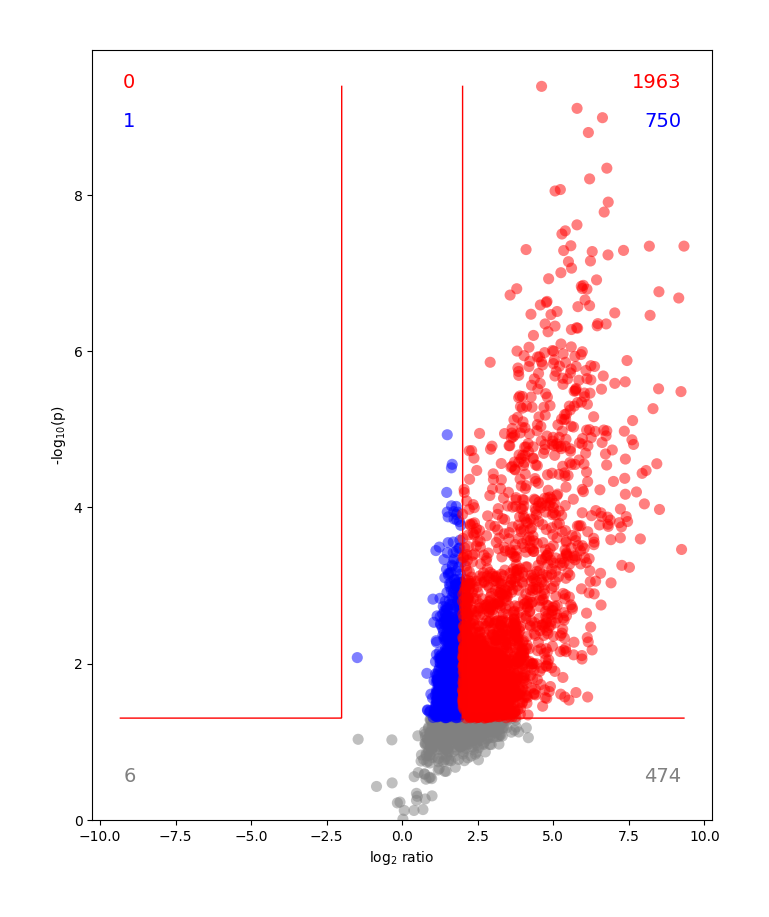

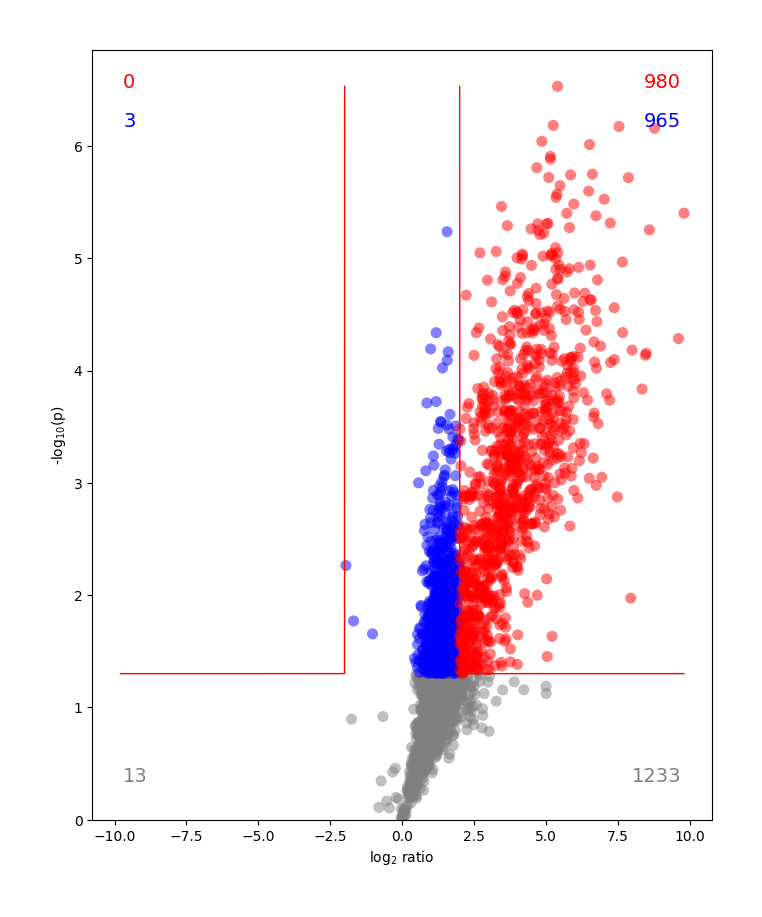

In [12]:
# pad2_vs_control_10 = volcano_data(imputed, 'pad2_10', 'control')
control_vs_pad4_10 = volcano_data(imputed, 'control', 'pad4_10')
control_vs_pad4_100 = volcano_data(imputed, 'control', 'pad4_100')
# pad2_vs_pad4_10 = volcano_data(imputed, 'pad2_10', 'pad4_10')
# pad2_vs_pad4_100 = volcano_data(imputed, 'pad2_100', 'pad4_100')
# pad4_100_vs_10 = volcano_data(imputed, 'pad4_100', 'pad4_10')

# use plotly express for volcano plot to allow interactive annotations

fig = go.Figure()
index= 0
comparisons = ['control_vs_pad4_10', 'control_vs_pad4_100']
for comparison in [control_vs_pad4_10, control_vs_pad4_100]:
    trace = go.Scatter(
    x = comparison['fc'],
    y = comparison['neg_log_pval'],
    mode='markers',
    hovertext=sites,
    name=comparisons[index],
    )
    fig.add_trace(trace)
    index += 1
fig.update_traces(textposition='top center')
fig.add_hline(y=(-np.log(0.05)))
fig.add_vline(x=2)
fig.add_vline(x=-2)
fig.show()

# save figure as vector
# fig.write_image('volcano_HEK.svg')

In [13]:
result, failed = mapper.get(
    ids=control_vs_pad4_100['protein'].to_list(), fields=['gene_names', 'protein_name']
)

Fetched: 264 / 265
Fetched: 174 / 174
Fetched: 201 / 201
Fetched: 215 / 215
Fetched: 283 / 283
Fetched: 316 / 316
Fetched: 99 / 99


In [14]:
# function to change protein names to chain names in nucleosome pdb 5y0c

def chain_names(names):
    new_names = list(re.sub('Histone H3.*', 'A,E', x) for x in names)
    new_names = list(re.sub('Histone H4.*', 'B,F', x) for x in new_names)
    new_names = list(re.sub('Histone H2A type 1.*', 'C,G', x) for x in new_names)
    new_names = list(re.sub('Histone H2B type 1.*', 'D,H', x) for x in new_names)
    new_names = list(re.sub('Histone.*', '', x) for x in new_names)

    return new_names

In [15]:
histones_sites = control_vs_pad4_100.set_index('protein').join(result.set_index('From')).dropna()
histones_sites = histones_sites[histones_sites['Gene Names'].str.contains('^H1|^H2|^H3|^H4')]
histones_sites['protein'] = list(x.split(' (')[0] for x in histones_sites['Protein names'])
histones_significant = histones_sites[histones_sites['significant'] == True]

chain = chain_names(histones_significant['protein'])
histones_significant['chain'] = chain

hbonds = 'hbonds '
for index, row in histones_significant.iterrows():
    if row['chain'] != '':
        hbond = '/' + str(row['chain']).split(',')[0] + ':' + str(int(row['site'])-1) + '@nh1,nh2'
        hbond += '/' + str(row['chain']).split(',')[1] + ':' + str(int(row['site'])-1) + '@nh1,nh2'
        hbonds += hbond
hbonds += ' col #6e306fff reveal t showDist f radius 0.15 dashes 0'
print(hbonds)

hbonds /D:79@nh1,nh2/H:79@nh1,nh2/D:92@nh1,nh2/H:92@nh1,nh2/C:29@nh1,nh2/G:29@nh1,nh2/C:32@nh1,nh2/G:32@nh1,nh2/C:88@nh1,nh2/G:88@nh1,nh2/C:81@nh1,nh2/G:81@nh1,nh2/C:3@nh1,nh2/G:3@nh1,nh2/C:20@nh1,nh2/G:20@nh1,nh2/C:17@nh1,nh2/G:17@nh1,nh2/B:23@nh1,nh2/F:23@nh1,nh2/A:72@nh1,nh2/E:72@nh1,nh2/A:49@nh1,nh2/E:49@nh1,nh2/A:26@nh1,nh2/E:26@nh1,nh2/C:20@nh1,nh2/G:20@nh1,nh2 col #6e306fff reveal t showDist f radius 0.15 dashes 0


C:\Users\kathe\AppData\Local\Temp\ipykernel_15656\3871911698.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  histones_significant['chain'] = chain


In [16]:
# gsea over representation analysis on only significantly increased genes
gene_list = control_vs_pad4_100[control_vs_pad4_100['significant'] == True].set_index('protein').join(result.set_index('From'))['Gene Names']
gene_list = [x.split(' ')[0] for x in gene_list]
gene_set = "C:/Users/kathe/Documents/Sanquin/Local_VS_analysis/COVID/QuickGO-annotations-hsa_slimBP.gmt"

enr = gseapy.enrichr(gene_list=gene_list,
                 gene_sets=gene_set,
                 organism='human',
                 outdir=None,
                )

# top 10 biological processes in terms of odds ratio
# filtered for categories that contain at least 5 genes
enriched_up = enr.results
enriched_up['number_of_genes'] = list(float(x.split('/')[0]) for x in enriched_up['Overlap'])
top_10_go = enriched_up[enriched_up['number_of_genes'] >= 5].sort_values('Odds Ratio', ascending=False)[0:10]
top_10_go['neg_log_pval'] = pd.Series(-np.log10(x) for x in top_10_go['Adjusted P-value']).to_numpy()
top_10_go

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes,number_of_genes,neg_log_pval
2,QuickGO-annotations-hsa_slimBP.gmt,GO:0002181,43/187,2.927323e-35,2.078399e-33,18.103975,1439.562720,RPS28;RPL7;RPL10A;SARS1;RPL5;VCP;RPL35A;HBS1L;...,43.0,32.682271
53,QuickGO-annotations-hsa_slimBP.gmt,GO:0042254,46/403,8.511973e-24,3.021750e-22,7.814067,415.087661,RPS28;PRKDC;RPL7;RPL5;RPL35A;MYG1;NOP58;RPS21;...,46.0,21.519741
28,QuickGO-annotations-hsa_slimBP.gmt,GO:0006913,29/313,4.254722e-13,4.315504e-12,6.046373,172.234412,YTHDC1;THOC1;ALYREF;HNRNPA2B1;RANBP2;EIF4A3;NU...,29.0,11.364968
0,QuickGO-annotations-hsa_slimBP.gmt,GO:0000278,52/584,9.210023e-22,2.179705e-20,5.958513,288.609989,PRKDC;SMC3;CLASP1;DYNC1H1;GPSM1;VCP;NUMA1;LIG1...,52.0,19.661602
50,QuickGO-annotations-hsa_slimBP.gmt,GO:0032200,13/146,2.016933e-06,6.819153e-06,5.753814,75.455127,PRKDC;RUVBL2;H4C1;XRCC5;LIG1;FEN1;RIF1;HSP90AA...,13.0,5.166270
68,QuickGO-annotations-hsa_slimBP.gmt,GO:0140014,18/215,5.828693e-08,2.758915e-07,5.367419,89.409858,PDCD6IP;SMC3;CLASP1;SMC1A;ZNF207;LSM14A;CCDC86...,18.0,6.559262
36,QuickGO-annotations-hsa_slimBP.gmt,GO:0007059,30/376,7.695744e-12,6.829973e-11,5.132164,131.333902,SMC3;CLASP1;NUMA1;PRC1;FLNA;NIPBL;CLTB;MAPRE1;...,30.0,10.165581
38,QuickGO-annotations-hsa_slimBP.gmt,GO:0007163,18/226,1.242212e-07,5.512314e-07,5.082466,80.817321,MSN;LMNA;NSFL1C;CLASP1;DST;GPSM1;PPFIA1;PDCD6I...,18.0,6.258666
22,QuickGO-annotations-hsa_slimBP.gmt,GO:0006457,29/398,1.512598e-10,1.193272e-09,4.642836,104.983910,HSPD1;TXNDC5;TBCE;CCT4;DNAJC7;HSPE1;MESD;RANBP...,29.0,8.923261
4,QuickGO-annotations-hsa_slimBP.gmt,GO:0003012,23/319,1.477597e-08,1.049094e-07,4.568893,82.378335,RPL7;RPL10A;RPL5;RPL35A;RPL29;ATP1A1;HSP90AA1;...,23.0,6.979186


In [17]:
# gsea over representation analysis on only significantly increased genes
# gsea over representation analysis on only significantly increased genes
gene_list = control_vs_pad4_100[control_vs_pad4_100['significant'] == True].set_index('protein').join(result.set_index('From'))['Gene Names']
gene_list = [x.split(' ')[0] for x in gene_list]
gene_set = "KEGG_2021_Human"

enr = gseapy.enrichr(gene_list=gene_list,
                 gene_sets=gene_set,
                 organism='human',
                 outdir=None,
                )

# top 10 biological processes in terms of odds ratio
# filtered for categories that contain at least 5 genes
enriched_up = enr.results
enriched_up['number_of_genes'] = list(float(x.split('/')[0]) for x in enriched_up['Overlap'])
top_10_kegg = enriched_up[enriched_up['number_of_genes'] >= 5].sort_values('Odds Ratio', ascending=False)[0:10]
top_10_kegg['neg_log_pval'] = pd.Series(-np.log10(x) for x in top_10_kegg['Adjusted P-value']).to_numpy()
top_10_kegg

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,number_of_genes,neg_log_pval
0,KEGG_2021_Human,Spliceosome,48/150,4.632030e-35,1.125583e-32,0,0,15.469986,1223.018153,ISY1;TCERG1;DDX5;RBM25;SF3B2;SF3B3;RBM8A;EIF4A...,48.0,31.948622
6,KEGG_2021_Human,Citrate cycle (TCA cycle),9/30,2.406701e-07,8.354690e-06,0,0,13.265143,202.158638,CS;ACLY;PDHA1;MDH1;IDH2;IDH3B;ACO2;SDHA;DLD,9.0,5.078070
1,KEGG_2021_Human,Ribosome,32/158,3.515044e-17,4.270778e-15,0,0,8.116859,307.522587,RPL5;RPL32;RPL10;RPL31;RPL12;RPS27L;MRPL15;RPL...,32.0,14.369493
16,KEGG_2021_Human,Glyoxylate and dicarboxylate metabolism,6/30,3.071614e-04,4.390601e-03,0,0,7.699841,62.277370,CS;MDH1;SHMT2;ACO2;DLD;ACAT2,6.0,2.357476
13,KEGG_2021_Human,Proteasome,9/46,1.178053e-05,2.044763e-04,0,0,7.522638,85.374886,PSMD6;PSMD11;PSMC3;PSMD2;PSMD3;PSMC2;PSME1;PSM...,9.0,3.689357
18,KEGG_2021_Human,Base excision repair,6/33,5.285351e-04,6.746041e-03,0,0,6.843241,51.635002,FEN1;LIG1;PARP1;APEX1;LIG3;HMGB1,6.0,2.170951
23,KEGG_2021_Human,DNA replication,6/36,8.575735e-04,8.682932e-03,0,0,6.157962,43.483854,POLA1;FEN1;LIG1;MCM3;MCM4;MCM2,6.0,2.061334
3,KEGG_2021_Human,RNA transport,30/186,2.047341e-13,1.243760e-11,0,0,6.116276,178.699633,NUP107;RBM8A;EIF4A3;PNN;TPR;NUP62;SAP18;EIF4B;...,30.0,10.905264
10,KEGG_2021_Human,Glycolysis / Gluconeogenesis,11/67,7.627041e-06,1.684883e-04,0,0,6.088340,71.743843,GPI;PKM;PDHA1;ALDH2;ALDH1B1;PGAM1;ENO1;ENO2;DL...,11.0,3.773430
15,KEGG_2021_Human,Arginine and proline metabolism,8/50,1.615852e-04,2.454076e-03,0,0,5.879811,51.333563,OAT;ALDH2;ALDH1B1;GOT1;GOT2;SMS;CKB;PRODH,8.0,2.610112


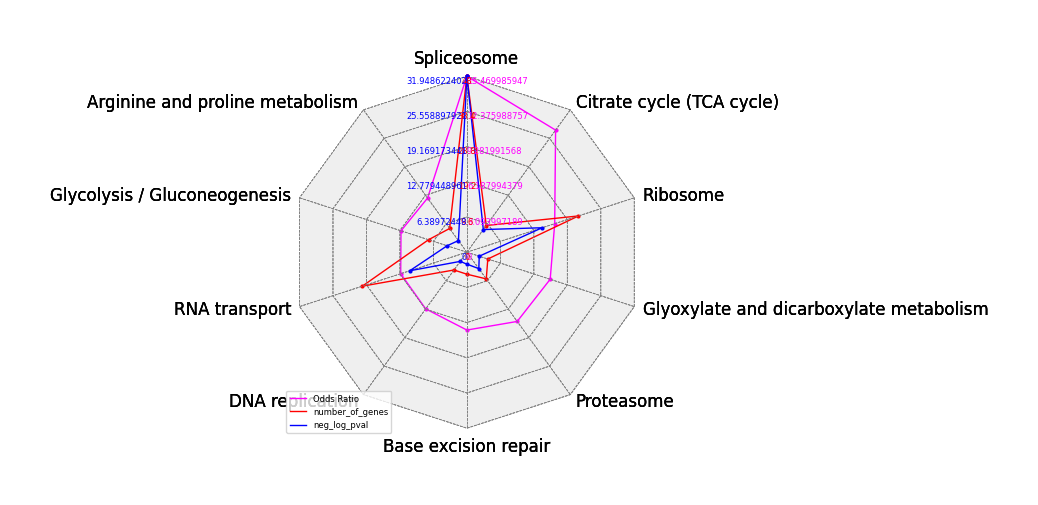

In [18]:
top_10_kegg_plot_data = pd.DataFrame(top_10_kegg.drop(columns=['Gene_set', 'Overlap', 'Old P-value', 'Genes', 'Term', 'Old Adjusted P-value', 'P-value', 'Adjusted P-value', 'Combined Score'])).T
top_10_kegg_plot_data.columns = top_10_kegg['Term']

fig, ax = plt.subplots(subplot_kw=dict(polar=True))
index = 0

cmaps = ['spring', 'autumn', 'winter', 'cool']
single_colours = ['fuchsia', 'red', 'blue', 'cyan']
align = ['left', 'center', 'right', 'left', 'center', 'right']

# Plot radar chart into subplots for each target
for target_name in top_10_kegg_plot_data.index:
    target_df = top_10_kegg_plot_data.loc[[target_name]]


    # Initialize Circos instance for radar chart plot
    circos = Circos.radar_chart(
        target_df,
        vmax=target_df.max(axis=None),
        vmin=0,
        marker_size=3,
        grid_interval_ratio=0.2,
        fill=False,
        cmap=cmaps[index],
        line_kws_handler=lambda _: dict(ls='solid'),
        grid_label_kws=dict(c=single_colours[index], ha=align[index], size=6),
    )

    # Plot figure & set legend on upper right
    circos.plotfig(ax=ax)
    circos.ax.legend(loc="lower left", fontsize=6)

    index += 1

# save figure as vector
# fig.savefig('hek_kegg_radar.svg')

In [19]:
# psalm = PSALM(model_name="ProteinSequenceAnnotation/PSALM-2")

In [21]:
seqs = [x.split(';')[0].replace('_', '.') for x in control_vs_pad4_100['sequence_window'][control_vs_pad4_100['significant'] == True]]
seqs = seqs + [x.split(';')[0].replace('_', '.') for x in control_vs_pad4_10['sequence_window'][control_vs_pad4_10['significant'] == True]]
seqs = pd.Series(seqs).unique().tolist()

index = 1
with open('pfam.fasta', 'w') as file:
    for seq in seqs:
        header = '>' + str(index)
        sequence = seq.strip('.')
        file.write(header + '\n')
        file.write(sequence + '\n')
        index += 1

In [22]:
# psalm_results = psalm.scan(fasta="pfam.fasta", to_tsv="psalm_results.tsv")
# print(psalm_results)

psalm_results = pd.read_csv('psalm_results.tsv', sep='\t')
psalm_counts = psalm_results.value_counts('Model')

psalm_sequences = pd.DataFrame({'Sequence' : np.arange(1,len(seqs) + 1),
                                'peptide' : seqs}).set_index('Sequence')

rrm_motif_peptides = psalm_results.set_index('Sequence').join(psalm_sequences)
rrm_motif_peptides = rrm_motif_peptides[rrm_motif_peptides['Model'] == 'RRM_1']

control_vs_pad4_100['index'] = pd.Series(x.split(';')[0].replace('_', '.') for x in control_vs_pad4_100['sequence_window']).drop(columns='sequence_window')

rrm_motif_proteins = rrm_motif_peptides.set_index('peptide').join(control_vs_pad4_100.set_index('index'))

seqs_rrm1 = [x.split(';')[0].replace('_', '.') for x in rrm_motif_proteins['sequence_window']]
seqs_rrm1 = pd.Series(seqs_rrm1).unique().tolist()

In [23]:
query_seq = []
entity = []
id = []
start_res = []
end_res = []
seq_start = []
chain = []
instance = []

for seq in seqs_rrm1:
    query = SeqSimilarityQuery(seq,
                               evalue_cutoff=0.01,
                               identity_cutoff=1,
                               sequence_type="protein",
                               )
    for polyid in query('polymer_entity', results_verbosity='verbose'):
        query_seq.append(seq)
        entity.append(list(polyid.values())[0].split('_')[0])
        id.append(list(polyid.values())[0].split('_')[1])
        start_res.append(str(list(polyid.values())[2]).split('\'subject_beg\': ')[1].split(',')[0])
        end_res.append(str(list(polyid.values())[2]).split('\'subject_beg\': ')[1].split(',')[1].split(' ')[2])
        seq_start.append(str(list(polyid.values())[2]).split('\'query_beg\': ')[1].split(',')[0])
        print(polyid)

pdbs = pd.DataFrame({'query_seq' : query_seq,
                     'entity' : entity,
                     'id' : [int(x) for x in id],
                     'start' : start_res,
                     'end' : end_res,
                     'seq_start' : seq_start,
                     })

pdbs_unique = pdbs.drop_duplicates(subset='query_seq').reset_index().drop(columns='index')

# index = 0
# for entity in pdbs_unique['entity']:
#     filename = str(entity) + '.cif'
#     if os.path.isfile(filename) == False:
#         query = ModelQuery()
#         result = query.get_atoms(entry_id=str(entity),
#                                     label_entity_id=str(pdbs_unique.loc[index, 'id']),
#                                     download=True,
#                                     filename=filename,
#                                     model_nums=[1],
#                                     )
#     index += 1

# index = 0
# for cif in pdbs_unique['entity']:
#     file = str(cif) + '.cif'
#     newfile = str(index) + '_' + str(cif) + '_v2' + '.cif'
#     with open(newfile, 'wt') as f:
#         chains = []
#         for line in open(file, 'rt'):
#             if line.startswith('ATOM') == False:
#                 f.write(line)
#             elif int(pdbs_unique.loc[index, 'start']) <= int(line.split(' ')[5]) <= int(pdbs_unique.loc[index, 'end']):
#                 f.write(line)
#     index += 1

# index = 0
# for cif in pdbs_unique['entity']:
#     file = str(index) + '_' + str(cif) + '_v2' + '.cif'
#     newfile = str(index) + '_' + str(cif) + '_v3' + '.cif'
#     with open(newfile, 'wt') as f:
#         chains = []
#         for line in open(file, 'rt'):
#             if line.startswith('ATOM'):
#                 chains.append(line.split(' ')[8])
#                 chain = chains[0]
#             else: f.write(line)
#             if line.startswith('ATOM') and line.split(' ')[8] == chain:
#                 f.write(line)
#     index += 1       

# index = 0
# pdb_files_final = []
# pdb_ids = []
# for pdb in pdbs_unique['entity']:
#     file = str(index) + '_' + str(pdb) + '.pdb'
#     newfile = str(index) + '_' + str(pdb) + '_v4' + '.pdb'
#     with open(newfile, 'wt', encoding='utf-8') as f2:
#         with open(file, 'rt') as f1:
#             f2.write(str(f1.readline()).replace('ATOM      1  N   ', 'ATOM      1  NH  '))
#             next(f1)
#             for line in f1:
#                 f2.write(line)
#     pdb_files_final.append(newfile)
#     pdb_ids.append(pdb)
#     index += 1

protein = []
site = []

for seq in pdbs_unique['query_seq']:
    protein.append(list(rrm_motif_proteins[rrm_motif_proteins.index == seq]['protein']))
    site.append(list(rrm_motif_proteins[rrm_motif_proteins.index == seq]['site']))
pdbs_unique['protein'] = list(str(x).strip('[]\'') for x in protein)
pdbs_unique['site'] = list(str(x).strip('[]\'') for x in site)



{'identifier': '2DK2_1', 'score': 1.0, 'services': [{'service_type': 'sequence', 'nodes': [{'node_id': 0, 'original_score': 66.0, 'norm_score': 1.0, 'match_context': [{'sequence_identity': 1.0, 'evalue': 3.778e-14, 'bitscore': 66, 'alignment_length': 31, 'mismatches': 0, 'gaps_opened': 0, 'query_beg': 1, 'query_end': 31, 'subject_beg': 44, 'subject_end': 74, 'query_length': 31, 'subject_length': 97, 'query_aligned_seq': 'RVKKLKDYAFVHFEDRGAAVKAMDEMNGKEI', 'subject_aligned_seq': 'RVKKLKDYAFVHFEDRGAAVKAMDEMNGKEI'}]}]}]}
{'identifier': '3CW1_9', 'score': 1.0, 'services': [{'service_type': 'sequence', 'nodes': [{'node_id': 0, 'original_score': 68.0, 'norm_score': 1.0, 'match_context': [{'sequence_identity': 1.0, 'evalue': 7.693e-15, 'bitscore': 68, 'alignment_length': 31, 'mismatches': 0, 'gaps_opened': 0, 'query_beg': 1, 'query_end': 31, 'subject_beg': 165, 'subject_end': 195, 'query_length': 31, 'subject_length': 216, 'query_aligned_seq': 'DGKKIDGRRVLVDVERGRTVKGWRPRRLGGG', 'subject_aligne

In [ ]:
colors = [
        #   "#39033bff",
          # "#2F4AA0",
          "#4282DC",
        #   '#d3f0d5',
          "#A1C6F9",
          "#B6D4FE",
          "#D9E9F9",
          "#F2FFFE",
          # '#ffffff',
          ]

custom_colours = sns.blend_palette(colors[::1],
                                   as_cmap=True,
                                   input='rgb',
                                   )

ax = plot(pdb_files_final,
          cmap=custom_colours,
          alpha=0.75,
          dpi=100,
          # save=True,
          show=False,
          # filename='rama_plot.svg',
          title=None,
          )

phi = []
psi = []
arg = []
phi_values = []
psi_values = []
index = 0
num = 1
for pdb in pdb_files_final:
    phi_psi = get_phi_psi(pdb, True, True)
    keys = list(phi_psi)
    if keys != []:
        arg = pdb.split('_')[1] + '-' + 'R' + keys[14].strip('A:ARG')
        phi = phi_psi[keys[14]][0]
        psi = phi_psi[keys[14]][1]
        phi_values += list(pd.DataFrame(phi_psi.values())[0])
        psi_values += list(pd.DataFrame(phi_psi.values())[1])
        plt.plot(phi, psi, 'bo')
        plt.text(phi, psi, num)
        print(str(num) + ' ' + pdbs_unique.loc[index, 'protein'] + ' ' + pdbs_unique.loc[index, 'site']) # needed for uniprot and rcsb lookup for figure
        num += 1
    else: print('missing')
    index += 1
plt.legend()
plt.savefig('rama_plot.svg', format='svg')

In [ ]:
# print('rainbow palette purples transparency 0')
# print('size pseudobondRadius 0.05 ballScale 0.05 atomRadius 0.05 stickRadius 0.05')
for index, pdb in pdbs_unique.iterrows():
    print(f'sel #{index + 1}/A:16')
    print('show sel a')
    print('col sel red target a')
    print('show sel models')
    print('~sel')
    print(f'save \'fig_{index}.png\' transparentBackground true')
    print('hide models')